# 02 · Preparación de datos: COCO → YOLO

**TP Visión por Computadora 2 — CEIA — Grupo 8**

Continuación de `01_exploracion_pklot.ipynb`. 

**Objetivo de este notebook:** deja los datos **listos para entrenar** con Ultralytics
(YOLO / RT-DETR) y para dejar el COCO disponible para torchvision (Faster R-CNN).

1. Carga los 3 splits oficiales (COCO) y recupera **cámara**, **fecha** y **hora** de cada imagen.
2. **Limpia**: descarta imágenes sin anotaciones (error de etiquetado), la supercategoría `spaces` y cajas degeneradas;
   recorta cajas que se salen de la imagen.
3. **Convierte** a formato YOLO (`class cx cy w h`, normalizado) sin duplicar imágenes (hardlink; si no se puede, copia).
4. Escribe un **COCO limpio único** (`annotations_clean.coco.json`) para torchvision / Detectron.
5. Genera **tres estrategias de split** como listas de archivos (sin copiar nada):
   - `oficial`: el split de Roboflow (comparable con otros trabajos, pero con *leakage* temporal).
   - `por_dia`: cada día completo cae en un único split (por cámara) → mide generalización a días nuevos.
   - `por_camara_<CAM>`: entrena con 2 cámaras y testea en la tercera → mide generalización a un estacionamiento nuevo.
6. Escribe un `data_*.yaml` por estrategia y un `metadata.csv` (cámara, fecha, hora, ocupación…) para evaluar por cámara después.
7. **Valida** todo (ida y vuelta COCO↔YOLO, conteos e inspección visual). El chequeo con Ultralytics se hace al inicio de
   `03_entrenamiento_yolo.ipynb`, que es donde Ultralytics ya es una dependencia.

**Salida** (en `datasets/pklot_yolo/`, relativo a la raíz del repo):

```
datasets/pklot_yolo/
├── images/all/*.jpg                 # todas las imágenes limpias (hardlinks o copias)
├── labels/all/*.txt                 # etiquetas YOLO
├── annotations_clean.coco.json      # COCO limpio (ids 1=space-empty, 2=space-occupied)
├── metadata.csv                     # una fila por imagen
├── <estrategia>_{train,valid,test}.txt
└── data_<estrategia>.yaml
```

## 0. Setup

In [1]:
import json
import os
import re
import shutil
import warnings
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import TqdmWarning

# Sin ipywidgets, tqdm.auto avisa (imprimiendo la ruta del .venv) y usa la barra de texto, que alcanza
warnings.filterwarnings("ignore", category=TqdmWarning)
from tqdm.auto import tqdm  # noqa: E402

%config InlineBackend.figure_format = "jpeg"  # mantiene liviano el .ipynb versionado
pd.set_option("display.max_columns", 50)

# El notebook vive en notebooks/, el dataset en /archive 
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "archive"
OUT_DIR = REPO_ROOT / "datasets" / "pklot_yolo"
SRC_SPLITS = ["train", "valid", "test"]
SPLITS = ["train", "valid", "test"]

SEED = 42
RNG = np.random.default_rng(SEED)

# Clases finales (orden = id YOLO). Se mapean por NOMBRE, no por id de Roboflow.
YOLO_CLASSES = ["space-empty", "space-occupied"]
CLASS_ID = {name: i for i, name in enumerate(YOLO_CLASSES)}

# La cámara no viene en los metadatos: se recupera por la cantidad de plazas anotadas (ver 01_exploracion)
CAMERA_BY_N = {100: "PUCPR", 40: "UFPR05", 28: "UFPR04"}
CAMERAS = ["PUCPR", "UFPR04", "UFPR05"]

# Proporciones de los splits "por_dia" y "por_camara" (train / valid / test)
FRACS_3 = {"train": 0.70, "valid": 0.15, "test": 0.15}
FRACS_2 = {"train": 0.85, "valid": 0.15}  # para las 2 cámaras de entrenamiento en por_camara

# Chequeo de que está todo lo necesario. Sólo se muestra ✓/✗ (sin rutas absolutas, que dependen de cada máquina).
_out_parent = next(p for p in [OUT_DIR, *OUT_DIR.parents] if p.exists())  # OUT_DIR se crea más abajo si no existe
checks = {
    "REPO_ROOT: raíz del repo (contiene notebooks/)": (REPO_ROOT / "notebooks").is_dir(),
    "DATA_DIR : archive/{train,valid,test}/_annotations.coco.json": all(
        (DATA_DIR / s / "_annotations.coco.json").is_file() for s in SRC_SPLITS),
    "OUT_DIR  : datasets/pklot_yolo/ se puede escribir": os.access(_out_parent, os.W_OK),
}
for what, ok in checks.items():
    print("✓" if ok else "✗", what)
assert all(checks.values()), "Falta algo (ver ✗ arriba). Para descargar el dataset en archive/, ver README."

✓ REPO_ROOT: raíz del repo (contiene notebooks/)
✓ DATA_DIR : archive/{train,valid,test}/_annotations.coco.json
✓ OUT_DIR  : datasets/pklot_yolo/ se puede escribir


## 1. Carga de los splits oficiales

Mismo procedimiento que en el EDA, pero guardando también `iw`/`ih` (tamaño real de cada imagen) para normalizar bien las cajas.

In [2]:
FNAME_RE = re.compile(r"^(\d{4}-\d{2}-\d{2})_(\d{2})_(\d{2})_(\d{2})")


def load_split(split: str):
    with open(DATA_DIR / split / "_annotations.coco.json", encoding="utf-8") as f:
        coco = json.load(f)
    cats = {c["id"]: c["name"] for c in coco["categories"]}

    imgs = pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]]
    imgs = imgs.rename(columns={"id": "image_id", "width": "iw", "height": "ih"})
    imgs["src_split"] = split

    anns = pd.DataFrame(coco["annotations"])[["id", "image_id", "category_id", "bbox"]]
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index).astype(float)
    anns = anns.drop(columns="bbox")
    anns["category"] = anns["category_id"].map(cats)
    anns["src_split"] = split
    return imgs, anns, cats


parts = [load_split(s) for s in SRC_SPLITS]
images = pd.concat([p[0] for p in parts], ignore_index=True)
annots = pd.concat([p[1] for p in parts], ignore_index=True)
CATS_RAW = parts[0][2]
del parts

# Fecha y hora de captura, codificadas en el nombre original del archivo
dt = images["file_name"].str.extract(FNAME_RE)
assert dt[0].notna().all(), "Hay nombres de archivo que no siguen el patrón YYYY-MM-DD_HH_MM_SS"
images["datetime"] = pd.to_datetime(dt[0] + " " + dt[1] + ":" + dt[2] + ":" + dt[3])
images["date"] = images["datetime"].dt.date.astype(str)
images["hour"] = images["datetime"].dt.hour

# Cámara por cantidad de anotaciones CRUDAS (antes de limpiar cajas)
n_raw = annots.groupby(["src_split", "image_id"]).size().rename("n_annots_raw")
images = images.merge(n_raw, left_on=["src_split", "image_id"], right_index=True, how="left")
images["n_annots_raw"] = images["n_annots_raw"].fillna(0).astype(int)
images["camera"] = images["n_annots_raw"].map(CAMERA_BY_N).fillna("otra")
images.loc[images["n_annots_raw"] == 0, "camera"] = "sin_anotar"

print("Categorías en el JSON:", CATS_RAW)
print(f"{len(images):,} imágenes | {len(annots):,} anotaciones")
print("Cámaras recuperadas:", images["camera"].value_counts().to_dict())
assert not (images["camera"] == "otra").any(), (
    "Hay imágenes con una cantidad de plazas distinta de 100/40/28: revisar CAMERA_BY_N")

Categorías en el JSON: {0: 'spaces', 1: 'space-empty', 2: 'space-occupied'}
12,416 imágenes | 711,856 anotaciones
Cámaras recuperadas: {'PUCPR': 4473, 'UFPR05': 4152, 'UFPR04': 3517, 'sin_anotar': 274}


## 2. Limpieza

Reglas justificadas en el EDA:

| Qué | Por qué | Acción |
|---|---|---|
| Imágenes sin anotaciones (274, UFPR04 vacío) | Error de etiquetado: las plazas existen pero no tienen caja | **Descartar** |
| Categoría `spaces` (id 0) | Supercategoría de Roboflow, no se usa en anotaciones | **Ignorar** (se verifica que nadie la use) |
| Cajas con ancho o alto ≤ 1 px tras recortar | Degeneradas | **Descartar** |
| Cajas que se salen de la imagen | Rompen el formato normalizado | **Recortar** a los bordes |

In [3]:
# --- categorías: se mapean por nombre ---
used = set(annots["category"].unique())
print("Categorías realmente usadas:", used)
assert used <= set(YOLO_CLASSES), f"Categorías inesperadas en las anotaciones: {used - set(YOLO_CLASSES)}"
annots["cls"] = annots["category"].map(CLASS_ID)

# --- recorte a los bordes de la imagen ---
annots = annots.merge(images[["src_split", "image_id", "iw", "ih"]], on=["src_split", "image_id"], how="left")
x1 = annots["x"].clip(lower=0)
y1 = annots["y"].clip(lower=0)
x2 = (annots["x"] + annots["w"]).clip(upper=annots["iw"])
y2 = (annots["y"] + annots["h"]).clip(upper=annots["ih"])
changed = ((x1 != annots["x"]) | (y1 != annots["y"]) | (x2 != annots["x"] + annots["w"]) | (y2 != annots["y"] + annots["h"]))
annots[["x", "y"]] = np.c_[x1, y1]
annots["w"], annots["h"] = x2 - x1, y2 - y1
degenerate = (annots["w"] <= 1) | (annots["h"] <= 1)

# --- imágenes sin anotaciones ---
no_ann = images["n_annots_raw"] == 0

report = pd.DataFrame({
    "cantidad": [int(no_ann.sum()), int(changed.sum()), int(degenerate.sum())],
}, index=["imágenes sin anotaciones (descartadas)", "cajas recortadas al borde", "cajas degeneradas (descartadas)"])
display(report)

annots = annots[~degenerate].copy()
images = images[~no_ann].copy()
# Una imagen puede quedar sin cajas si todas eran degeneradas: también se descarta
keep = annots.groupby(["src_split", "image_id"]).size().rename("n_annots")
images = images.merge(keep, left_on=["src_split", "image_id"], right_index=True, how="inner")
annots = annots.merge(images[["src_split", "image_id"]], on=["src_split", "image_id"], how="inner")

# Nombres de archivo únicos entre splits (todas las imágenes van a la misma carpeta)
assert images["file_name"].is_unique, "Hay nombres de archivo repetidos entre splits"

images = images.reset_index(drop=True)
images["occupancy"] = (annots.assign(o=annots["cls"] == CLASS_ID["space-occupied"])
                       .groupby(["src_split", "image_id"])["o"].mean()
                       .reindex(pd.MultiIndex.from_frame(images[["src_split", "image_id"]])).to_numpy())
# Cajas "libres" por imagen: se usa para balancear la proporción de clases entre splits (sección 3)
images["n_empty"] = (annots.assign(e=annots["cls"] == CLASS_ID["space-empty"])
                     .groupby(["src_split", "image_id"])["e"].sum()
                     .reindex(pd.MultiIndex.from_frame(images[["src_split", "image_id"]])).to_numpy())

print(f"\nTras limpiar: {len(images):,} imágenes | {len(annots):,} cajas")
pd.crosstab(images["camera"], images["src_split"], margins=True)

Categorías realmente usadas: {'space-empty', 'space-occupied'}


,cantidad
imágenes sin anotaciones (descartadas),274
cajas recortadas al borde,0
cajas degeneradas (descartadas),0



Tras limpiar: 12,142 imágenes | 711,856 cajas


src_split,test,train,valid,All
camera,,,,
PUCPR,438,3128,907,4473
UFPR04,353,2492,672,3517
UFPR05,425,2882,845,4152
All,1216,8502,2424,12142


## 3. Estrategias de split

El EDA mostró que el split oficial de Roboflow es **aleatorio por imagen**: todos los días de `valid`/`test` están en `train`
y la mediana de distancia al frame de train más cercano es de ~5 min. Es decir, el test oficial **sobreestima** el desempeño.

Armamos entonces tres estrategias, todas como listas de archivos (no se copian imágenes):

- **`oficial`**: los splits de Roboflow, tal cual (solo con la limpieza).
- **`por_dia`**: por cada cámara se reparten **días completos** entre train/valid/test (~70/15/15 por cantidad de imágenes).
- **`por_camara_<CAM>`**: test = **toda** la cámara `<CAM>` (nunca vista); train/valid = las otras dos cámaras, separadas por día (~85/15).

**Balance de clases entre splits.** Como se reparten días completos y la ocupación varía mucho de un día a otro,
un sorteo único puede dejar días muy vacíos en `valid` (con el sorteo inicial salió hasta ~79 % de `space-empty` en
`por_camara_PUCPR`, contra ~39 % en train). `valid` decide el *early stopping* y el `best.pt`, así que conviene que se parezca a `train`.
Por eso, para cada estrategia se prueban `N_SEEDS` sorteos (deterministas: `SEED`, `SEED+1`, …) y se elige el que minimiza
la diferencia de % de `space-empty` entre `valid` y `train` **más** el desvío del tamaño de cada split respecto de su cuota.
Las etiquetas de `test` **no** intervienen en la elección (sólo su tamaño), para no ajustar nada mirando el conjunto de evaluación.
Los días nunca se parten. El test de `por_camara_*` es una cámara completa, así que su balance no se puede ajustar (y es parte del objetivo).

In [4]:
def assign_by_group(df: pd.DataFrame, fracs: dict, seed: int) -> pd.Series:
    """Asigna cada imagen a un split garantizando que todos los frames de un mismo (cámara, día) queden juntos.

    Se hace por cámara: se mezclan los días y se asigna cada uno al split con mayor déficit relativo
    respecto de su cuota, de modo que las proporciones por imagen queden cerca de `fracs`.
    """
    rng = np.random.default_rng(seed)
    out = pd.Series(index=df.index, dtype=object)
    for cam, d in df.groupby("camera"):
        sizes = d.groupby("date").size()
        days = list(sizes.index)
        rng.shuffle(days)
        target = {s: f * len(d) for s, f in fracs.items()}
        current = {s: 0 for s in fracs}
        day_split = {}
        for day in days:
            # split con mayor déficit relativo
            s = max(fracs, key=lambda k: (target[k] - current[k]) / target[k])
            day_split[day] = s
            current[s] += sizes[day]
        out.loc[d.index] = d["date"].map(day_split)
    return out


N_SEEDS = 300  # sorteos a probar por estrategia (deterministas: SEED, SEED+1, ...)


def balance_score(df: pd.DataFrame, s: pd.Series, fracs: dict) -> float:
    """Puntos porcentuales de desvío: |%libres(valid) - %libres(train)| + |%imágenes(split) - cuota| para cada split.
    Las etiquetas de test no se miran (sólo su tamaño). Menor = mejor. inf si alguna cámara queda sin imágenes en algún split."""
    present = pd.crosstab(df["camera"], s).reindex(columns=list(fracs), fill_value=0)
    if (present == 0).any().any():
        return np.inf
    tot = df.groupby(s)[["n_empty", "n_annots"]].sum()
    pct_empty = 100 * tot["n_empty"] / tot["n_annots"]
    share = 100 * s.value_counts() / len(df)
    dev_class = abs(pct_empty["valid"] - pct_empty["train"])
    dev_size = sum(abs(share[k] - 100 * f) for k, f in fracs.items())
    return float(dev_class + dev_size)


def best_assignment(df: pd.DataFrame, fracs: dict, seed0: int = SEED, n_seeds: int = N_SEEDS):
    best_score, best_seed, best_s = np.inf, None, None
    for sd in range(seed0, seed0 + n_seeds):
        s = assign_by_group(df, fracs, sd)
        score = balance_score(df, s, fracs)
        if score < best_score:
            best_score, best_seed, best_s = score, sd, s
    assert best_s is not None, "Ningún sorteo dejó todas las cámaras presentes en todos los splits"
    return best_s, best_seed, best_score


strategies = {}  # nombre -> Series con el split de cada imagen (índice = images.index)
search_log = {}  # nombre -> (semilla elegida, score)

# 1) oficial
strategies["oficial"] = images["src_split"]

# 2) por día
s, sd, sc = best_assignment(images, FRACS_3)
strategies["por_dia"], search_log["por_dia"] = s, (sd, sc)

# 3) por cámara (leave-one-camera-out)
for holdout in CAMERAS:
    s = pd.Series(index=images.index, dtype=object)
    is_hold = images["camera"] == holdout
    s[is_hold] = "test"
    s_train, sd, sc = best_assignment(images[~is_hold], FRACS_2)
    s[~is_hold] = s_train
    strategies[f"por_camara_{holdout}"] = s
    search_log[f"por_camara_{holdout}"] = (sd, sc)

# --- verificaciones de integridad ---
for name, s in strategies.items():
    assert s.notna().all() and set(s.unique()) <= set(SPLITS), name
    if name != "oficial":
        # ningún (cámara, día) cruza splits
        n_splits_per_group = images.assign(s=s).groupby(["camera", "date"])["s"].nunique()
        assert (n_splits_per_group == 1).all(), f"{name}: hay días repartidos en más de un split"
    for sp in SPLITS:
        assert (s == sp).any(), f"{name}: el split {sp} quedó vacío"
print("OK: sin días cruzando splits (por_dia / por_camara) y sin splits vacíos.")
print("Semilla elegida (score = puntos porcentuales de desvío):",
      {k: (sd, round(sc, 2)) for k, (sd, sc) in search_log.items()})

summary = pd.concat({n: s.value_counts().reindex(SPLITS) for n, s in strategies.items()}, axis=1).T
summary["% test"] = (100 * summary["test"] / summary.sum(axis=1)).round(1)
summary

OK: sin días cruzando splits (por_dia / por_camara) y sin splits vacíos.
Semilla elegida (score = puntos porcentuales de desvío): {'por_dia': (110, 1.15), 'por_camara_PUCPR': (293, 0.91), 'por_camara_UFPR04': (120, 0.79), 'por_camara_UFPR05': (297, 0.3)}


,train,valid,test,% test
oficial,8502,2424,1216,10.0
por_dia,8449,1888,1805,14.9
por_camara_PUCPR,6511,1158,4473,36.8
por_camara_UFPR04,7304,1321,3517,29.0
por_camara_UFPR05,6802,1188,4152,34.2


In [5]:
# Composición por cámara de cada split y del test (¿hay de todo en todos lados?)
comp = []
for name, s in strategies.items():
    ct = pd.crosstab(images["camera"], s).reindex(columns=SPLITS, fill_value=0)
    ct.columns = pd.MultiIndex.from_product([[name], ct.columns])
    comp.append(ct)
pd.concat(comp, axis=1)

oficial            por_dia            por_camara_PUCPR              \
         train valid test   train valid test            train valid  test   
camera                                                                      
PUCPR     3128   907  438    3079   734  660                0     0  4473   
UFPR04    2492   672  353    2462   538  517             2962   555     0   
UFPR05    2882   845  425    2908   616  628             3549   603     0   

       por_camara_UFPR04             por_camara_UFPR05              
                   train valid  test             train valid  test  
camera                                                              
PUCPR               3797   676     0              3809   664     0  
UFPR04                 0     0  3517              2993   524     0  
UFPR05              3507   645     0                 0     0  4152

In [6]:
# ¿Se arregló el leakage? Minutos desde cada frame de test hasta el frame de train más cercano (misma cámara)
def gap_to_train(split_series: pd.Series) -> pd.Series:
    tr = images[split_series == "train"].sort_values("datetime")
    te = images[split_series == "test"].sort_values("datetime")
    if te.empty or tr.empty:
        return pd.Series(dtype=float)
    near = pd.merge_asof(te[["datetime", "camera"]], tr[["datetime", "camera"]].rename(columns={"datetime": "dt_tr"}),
                         left_on="datetime", right_on="dt_tr", by="camera", direction="nearest")
    return (near["datetime"] - near["dt_tr"]).abs().dt.total_seconds().div(60)

rows = {}
for name, s in strategies.items():
    g = gap_to_train(s)
    rows[name] = g.describe(percentiles=[0.5, 0.9]).round(1) if len(g) else pd.Series(dtype=float)
leak = pd.DataFrame(rows).T[["count", "min", "50%", "90%"]]
leak.columns = ["frames test c/ cámara en train", "mín (min)", "mediana (min)", "p90 (min)"]
leak

,frames test c/ cámara en train,mín (min),mediana (min),p90 (min)
oficial,1216.0,0.1,5.0,10.0
por_dia,1805.0,649.8,1049.9,2538.3
por_camara_PUCPR,0.0,NaN,NaN,NaN
por_camara_UFPR04,0.0,NaN,NaN,NaN
por_camara_UFPR05,0.0,NaN,NaN,NaN


> En `oficial` la mediana está en minutos (leakage). En `por_dia` el frame de train más cercano está como mínimo a varias horas,
> y en `por_camara_*` las cámaras de test directamente no existen en train (por eso la columna cuenta 0 frames: no hay con qué comparar).

## 4. Escritura: imágenes, etiquetas YOLO y COCO limpio

- Las imágenes se **enlazan** (hardlink) a `images/all/` para no duplicar disco; si el sistema de archivos no lo permite se copian.
- Ultralytics deduce la carpeta de etiquetas reemplazando `/images/` por `/labels/` en la ruta de cada imagen,
  por eso la estructura `images/all` ↔ `labels/all`.
- Formato YOLO: `class cx cy w h`, todo normalizado a [0, 1] por el tamaño real de la imagen.

In [7]:
# Se regenera todo desde cero para no dejar archivos viejos si cambian las reglas de limpieza
if OUT_DIR.exists():
    assert OUT_DIR.name == "pklot_yolo"  # protección: sólo borramos nuestra propia carpeta de salida
    shutil.rmtree(OUT_DIR)
(OUT_DIR / "images" / "all").mkdir(parents=True)
(OUT_DIR / "labels" / "all").mkdir(parents=True)

# YOLO normalizado
annots["cx"] = (annots["x"] + annots["w"] / 2) / annots["iw"]
annots["cy"] = (annots["y"] + annots["h"] / 2) / annots["ih"]
annots["nw"] = annots["w"] / annots["iw"]
annots["nh"] = annots["h"] / annots["ih"]
assert annots[["cx", "cy", "nw", "nh"]].to_numpy().min() >= 0
assert annots[["cx", "cy", "nw", "nh"]].to_numpy().max() <= 1 + 1e-9

grouped = {k: g for k, g in annots.groupby(["src_split", "image_id"])}
link_fallbacks = 0
for row in tqdm(images.itertuples(index=False), total=len(images), desc="imágenes + etiquetas"):
    src = DATA_DIR / row.src_split / row.file_name
    dst = OUT_DIR / "images" / "all" / row.file_name
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)
        link_fallbacks += 1

    g = grouped[(row.src_split, row.image_id)]
    lines = [f"{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}"
             for c, cx, cy, w, h in zip(g["cls"], g["cx"], g["cy"], g["nw"], g["nh"])]
    (OUT_DIR / "labels" / "all" / (Path(row.file_name).stem + ".txt")).write_text("\n".join(lines) + "\n", encoding="utf-8", newline="\n")

print(f"{len(images):,} imágenes y etiquetas escritas ({link_fallbacks} copiadas por no poder hacer hardlink)")

imágenes + etiquetas: 100%|██████████| 12142/12142 [01:27<00:00, 138.50it/s]

12,142 imágenes y etiquetas escritas (0 copiadas por no poder hacer hardlink)


In [8]:
# COCO limpio único (para torchvision / Detectron). Conserva los ids originales: 1 = space-empty, 2 = space-occupied
# (el 0 queda libre para 'background', como espera Faster R-CNN de torchvision).
coco_ids = {"space-empty": 1, "space-occupied": 2}
img_new_id = {(r.src_split, r.image_id): i for i, r in enumerate(images.itertuples(index=False), start=1)}

coco_out = {
    "info": {"description": "PKLot (Roboflow v2 640) limpio - Grupo 8 VpC2"},
    "categories": [{"id": i, "name": n} for n, i in coco_ids.items()],
    "images": [
        {"id": img_new_id[(r.src_split, r.image_id)], "file_name": f"images/all/{r.file_name}",
         "width": int(r.iw), "height": int(r.ih), "camera": r.camera, "date": r.date, "hour": int(r.hour)}
        for r in images.itertuples(index=False)
    ],
    "annotations": [
        {"id": k, "image_id": img_new_id[(a.src_split, a.image_id)],
         "category_id": coco_ids[YOLO_CLASSES[int(a.cls)]],
         "bbox": [round(a.x, 2), round(a.y, 2), round(a.w, 2), round(a.h, 2)],
         "area": round(a.w * a.h, 2), "iscrowd": 0}
        for k, a in enumerate(annots.itertuples(index=False), start=1)
    ],
}
with open(OUT_DIR / "annotations_clean.coco.json", "w", encoding="utf-8") as f:
    json.dump(coco_out, f)
print(f"COCO limpio: {len(coco_out['images']):,} imágenes, {len(coco_out['annotations']):,} cajas")
del coco_out

COCO limpio: 12,142 imágenes, 711,856 cajas


## 5. Listas de split, `data_*.yaml` y `metadata.csv`

Cada estrategia se define con 3 archivos `.txt` (una ruta por imagen) y un `.yaml`. Las rutas son **relativas** (`./images/all/...`),
así el dataset funciona igual en macOS, Windows o Colab sin tocar nada. El `.yaml` no define `path`, por lo que Ultralytics
usa la carpeta donde está el `.yaml`.

In [9]:
for name, s in strategies.items():
    for sp in SPLITS:
        files = images.loc[s == sp, "file_name"].sort_values()
        (OUT_DIR / f"{name}_{sp}.txt").write_text("\n".join(f"./images/all/{f}" for f in files) + "\n",
                                                encoding="utf-8", newline="\n")

    yaml = (
        f"# Estrategia de split: {name}\n"
        f"train: {name}_train.txt\n"
        f"val: {name}_valid.txt\n"
        f"test: {name}_test.txt\n"
        f"nc: {len(YOLO_CLASSES)}\n"
        f"names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(YOLO_CLASSES))
    )
    (OUT_DIR / f"data_{name}.yaml").write_text(yaml, encoding="utf-8", newline="\n")

meta = images[["file_name", "camera", "date", "hour", "datetime", "n_annots", "occupancy", "src_split"]].copy()
for name, s in strategies.items():
    meta[f"split_{name}"] = s
meta.to_csv(OUT_DIR / "metadata.csv", index=False, encoding="utf-8", lineterminator="\n")

print(sorted(p.name for p in OUT_DIR.glob("*.yaml")))
print((OUT_DIR / "data_por_dia.yaml").read_text(encoding="utf-8"))

['data_oficial.yaml', 'data_por_camara_PUCPR.yaml', 'data_por_camara_UFPR04.yaml', 'data_por_camara_UFPR05.yaml', 'data_por_dia.yaml']
# Estrategia de split: por_dia
train: por_dia_train.txt
val: por_dia_valid.txt
test: por_dia_test.txt
nc: 2
names:
  0: space-empty
  1: space-occupied



## 6. Validaciones

In [10]:
# 6.1 Conteos: una etiqueta por imagen, y las listas de cada estrategia cubren exactamente todas las imágenes
n_img = len(list((OUT_DIR / "images" / "all").glob("*.jpg")))
n_lab = len(list((OUT_DIR / "labels" / "all").glob("*.txt")))
assert n_img == n_lab == len(images), (n_img, n_lab, len(images))
for name in strategies:
    listed = []
    for sp in SPLITS:
        listed += (OUT_DIR / f"{name}_{sp}.txt").read_text(encoding="utf-8").split()
    assert len(listed) == len(set(listed)) == len(images), name  # sin repetidos ni faltantes
print(f"OK: {n_img:,} imágenes = {n_lab:,} etiquetas; cada estrategia cubre todas las imágenes exactamente una vez.")

# 6.2 Balance de clases por split y estrategia (a nivel de cajas)
ann_cls = annots.merge(images[["src_split", "image_id"]].assign(idx=images.index), on=["src_split", "image_id"])
rows = []
for name, s in strategies.items():
    sp = ann_cls["idx"].map(s)
    pct = ann_cls.assign(sp=sp).groupby("sp")["cls"].apply(lambda c: 100 * (c == CLASS_ID["space-empty"]).mean())
    rows.append(pct.reindex(SPLITS).rename(name))
print("\n% de cajas 'space-empty' por split:")
pd.DataFrame(rows).round(1)

OK: 12,142 imágenes = 12,142 etiquetas; cada estrategia cubre todas las imágenes exactamente una vez.


% de cajas 'space-empty' por split:


sp,train,valid,test
oficial,53.4,51.4,51.8
por_dia,53.6,53.6,48.2
por_camara_PUCPR,45.6,46.4,57.0
por_camara_UFPR04,52.8,52.6,53.2
por_camara_UFPR05,56.3,56.3,41.3


In [11]:
# 6.3 Ida y vuelta YOLO -> píxeles vs. COCO limpio (muestra de 300 imágenes)
sample = images.sample(min(300, len(images)), random_state=0)
max_err = 0.0
for r in sample.itertuples(index=False):
    lab = np.loadtxt(OUT_DIR / "labels" / "all" / (Path(r.file_name).stem + ".txt"), ndmin=2)
    g = grouped[(r.src_split, r.image_id)]
    assert len(lab) == len(g)
    back = np.c_[(lab[:, 1] - lab[:, 3] / 2) * r.iw, (lab[:, 2] - lab[:, 4] / 2) * r.ih, lab[:, 3] * r.iw, lab[:, 4] * r.ih]
    ref = g[["x", "y", "w", "h"]].to_numpy()
    assert (lab[:, 0] == g["cls"].to_numpy()).all()
    max_err = max(max_err, np.abs(back - ref).max())
print(f"Error máximo de la conversión (px): {max_err:.5f}")
assert max_err < 0.01

Error máximo de la conversión (px): 0.00032


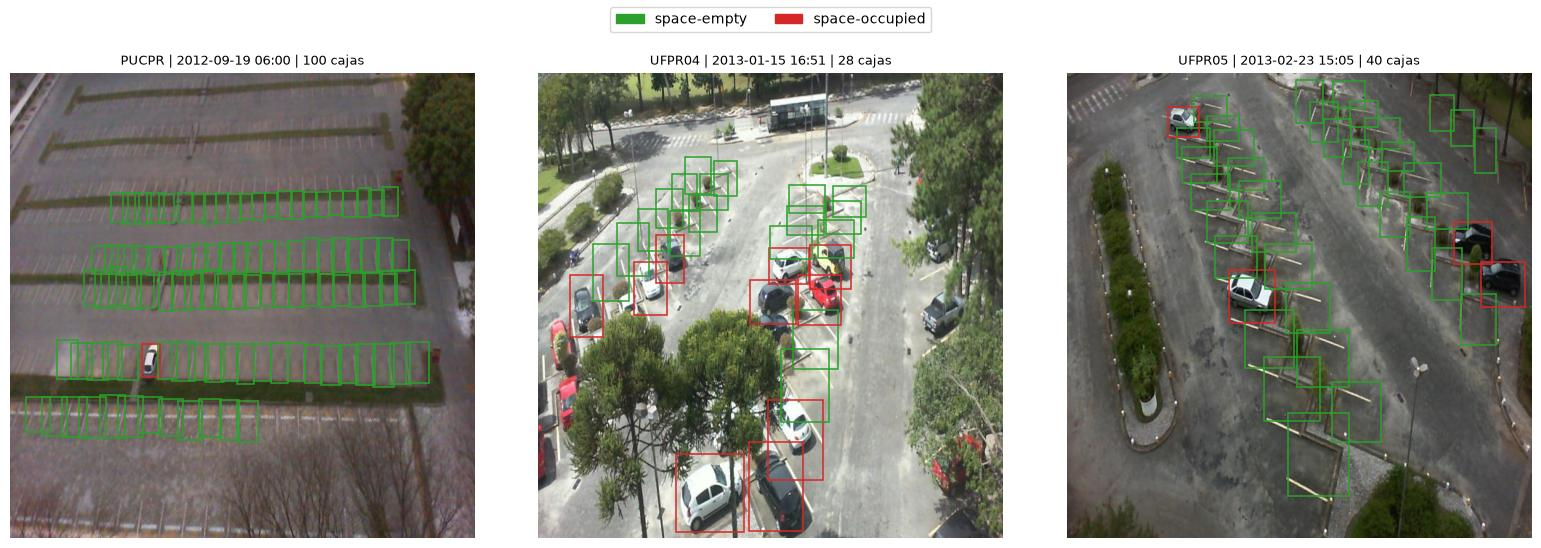

In [12]:
# 6.4 Inspección visual: se leen las etiquetas YOLO ESCRITAS (no los DataFrames) y se dibujan sobre la imagen
PALETTE = {0: "#2ca02c", 1: "#d62728"}  # empty verde, occupied rojo


def show_yolo(file_name: str, ax):
    img = Image.open(OUT_DIR / "images" / "all" / file_name)
    W, H = img.size
    lab = np.loadtxt(OUT_DIR / "labels" / "all" / (Path(file_name).stem + ".txt"), ndmin=2)
    ax.imshow(img)
    for c, cx, cy, w, h in lab:
        ax.add_patch(mpatches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, lw=1.1, ec=PALETTE[int(c)]))
    row = images[images["file_name"] == file_name].iloc[0]
    ax.set_title(f"{row['camera']} | {row['datetime']:%Y-%m-%d %H:%M} | {len(lab)} cajas", fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, cam in zip(axes, CAMERAS):
    show_yolo(images[images["camera"] == cam].sample(1, random_state=7)["file_name"].iloc[0], ax)
fig.legend(handles=[mpatches.Patch(color=PALETTE[i], label=n) for i, n in enumerate(YOLO_CLASSES)], loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.9))

### 6.5 Chequeo con Ultralytics

Se hace al inicio de `03_entrenamiento_yolo.ipynb` (ahí Ultralytics ya es una dependencia y el chequeo falla antes de gastar GPU): verifica los `data_*.yaml` y compara, para cada estrategia y split, las imágenes que Ultralytics realmente lee contra `metadata.csv`.

## 7. Cómo usar los resultados

**Entrenar con Ultralytics** (cambiando el `.yaml` se cambia la estrategia de evaluación):

```python
from ultralytics import YOLO

model = YOLO("yolo11m.pt")  # pesos preentrenados en COCO (transfer learning)
model.train(
    data="datasets/pklot_yolo/data_por_dia.yaml",
    imgsz=640, epochs=50, batch=16,
    device=0,        # GPU NVIDIA (Colab/Windows). En Mac: "mps"; sin GPU: "cpu"
)
```

**torchvision / Detectron:** usar `annotations_clean.coco.json` (ids 1 y 2; el 0 queda para *background*) y filtrar las
imágenes con las listas `<estrategia>_<split>.txt` (el nombre de archivo coincide con el campo `file_name`).

**Evaluar por cámara:** `metadata.csv` trae la cámara, fecha, hora y el split de cada estrategia por imagen.

**Próximos pasos**
1. Entrenar y comparar al menos dos arquitecturas, p. ej.:
   - **One-stage:** YOLOv8/YOLO11 (Ultralytics).
   - **Two-stage o transformer:** Faster R-CNN (torchvision) o RT-DETR.
2. Métricas: precision, recall, F1, mAP@0.5 y mAP@0.5:0.95 (global, por clase y por cámara), y tiempo de
   inferencia (ms/imagen, FPS) en el mismo hardware.
3. Post-proceso: % de ocupación por frame (ocupados / total detectado) y comparación con el ground truth.
4. Demo: conseguir un video corto de un estacionamiento (vista elevada fija), inferir frame a frame y
   superponer conteo de libres/ocupados. Evaluar suavizado temporal para estabilizar el conteo.